# Xác định lòng đường: HSV → Canny → Hough

Notebook chạy trọn chuỗi xử lý của đồ án trên 50 ảnh trong `dataset/images`, từ đầu đến cuối, và hiển thị kết quả sau mỗi bước. Mục tiêu là **vùng lòng đường** (ground truth là mặt nạ lòng đường), không phải vạch kẻ làn.

1. **Tiền xử lý HSV → mặt nạ lòng đường**: resize 960×540 → RGB sang HSV → CLAHE trên V → vạch sơn (white top-hat) → điểm tụ → mô hình màu mặt đường (S, V) học từ cửa sổ ngay trước xe → quét từng hàng từ cửa sổ mẫu (ràng buộc phối cảnh, dừng ở chân trời và nắp capo) → mặt nạ lòng đường, làm mờ Gaussian thành `canny_input`.
2. **Canny** (cài bằng NumPy) trên mặt nạ lòng đường: cạnh thu được là ranh giới lòng đường, không còn mép vạch sơn.
3. **Hough**: ROI thích nghi (dải từ chân trời tới mép capo) → P-Hough → lọc độ dốc trái/phải (|m| ≥ 0,10) → nhiều ứng viên biên mỗi bên → chọn cặp biên khớp nhất với mặt nạ lòng đường HSV → đa giác lòng đường (đi dọc mép ảnh khi biên ra khỏi khung).
4. **Đánh giá trên mặt nạ**: IoU, precision, recall, F1, MAE theo mép trái/phải và SR15, tổng hợp theo nhóm `normal / curved / adverse`.
5. **So sánh** với bản gốc, bản trước và một baseline tầm thường.

Canny chép nguyên từ `canny.py`. Các hàm Hough cũ chép từ `hough.py` và được giữ lại để tái tạo bản gốc ở Bước 5. Tiền xử lý, ROI, hậu xử lý Hough mới và cách đánh giá trên mặt nạ chỉ có trong notebook; các file `.py` giữ nguyên.

**Cách chạy:** mở notebook ở thư mục gốc dự án (hoặc trên Colab, xem ô đầu tiên) rồi chọn *Run All*. Ô đầu tiên mở hộp thoại chọn một hoặc nhiều ảnh làm đầu vào; bấm *Cancel* (hoặc chạy trên Colab, hoặc đặt biến môi trường `PIPELINE_NO_PICKER=1` khi chạy tự động) thì dùng cả 50 ảnh của dataset. Ảnh không có ground truth vẫn chạy đủ các bước, chỉ bị bỏ qua ở bước đánh giá. Kết quả ghi vào `outputs/pipeline_notebook/`, không ghi đè thư mục `outputs/` của từng phần.


In [1]:
from dataclasses import asdict, dataclass
from pathlib import Path
import os
import time

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageFilter, ImageOps

# Neu chay tren Google Colab voi Drive, bo dau # o hai dong sau.
# from google.colab import drive
# drive.mount('/content/drive')

candidates = [Path.cwd(), Path.cwd().parent, Path('/content/Bai_Tap_Lon'), Path('/content/drive/MyDrive/Bai_Tap_Lon')]
ROOT = next((p for p in candidates if (p / 'dataset' / 'images').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Khong tim thay dataset/images. Hay mount Drive hoac sua candidates.')

IMAGE_DIR = ROOT / 'dataset' / 'images'
GT_DIR = ROOT / 'dataset' / 'ground_truth'
OUT = ROOT / 'outputs' / 'pipeline_notebook'
GROUPS = ['normal', 'curved', 'adverse']
SAMPLES = [('normal', 'normal_05'), ('curved', 'curved_05'), ('adverse', 'adverse_13')]

image_paths = sorted(p for g in GROUPS for p in (IMAGE_DIR / g).iterdir()
                     if p.suffix.lower() in {'.jpg', '.jpeg', '.png', '.bmp', '.webp'})

# Hop thoai chon anh dau vao. Bam Cancel, hoac moi truong khong co man hinh (Colab), thi dung ca dataset.
try:
    if os.environ.get('PIPELINE_NO_PICKER'):  # chay tu dong (nbclient, CI): dung ca dataset
        raise RuntimeError
    import tkinter as tk
    from tkinter import filedialog
    tk_root = tk.Tk()
    tk_root.withdraw()
    tk_root.attributes('-topmost', True)  # de hop thoai khong bi an sau cua so Jupyter
    picked = filedialog.askopenfilenames(parent=tk_root, title='Chon mot hoac nhieu anh', initialdir=IMAGE_DIR,
                                         filetypes=[('Anh', '*.jpg *.jpeg *.png *.bmp *.webp'), ('Tat ca', '*.*')])
    tk_root.destroy()
except Exception:
    picked = ()
if picked:
    image_paths = [Path(p) for p in picked]

NAMES = [(p.parent.name, p.stem) for p in image_paths]
# Anh mau de ve hinh: giu anh mau mac dinh neu co trong danh sach, neu khong lay toi da 3 anh dau
SAMPLES = [k for k in SAMPLES if k in NAMES] or NAMES[:3]
print('ROOT =', ROOT)
print('So anh =', len(NAMES), {g: sum(1 for x, _ in NAMES if x == g) for g in GROUPS})


def show(rows, titles, figsize_per=(5, 2.9)):
    # Ve luoi anh: moi hang mot anh mau, moi cot mot buoc
    fig, axes = plt.subplots(len(rows), len(titles), figsize=(figsize_per[0] * len(titles), figsize_per[1] * len(rows)))
    axes = np.atleast_2d(axes)
    for r, (label, panels) in enumerate(rows):
        for c, img in enumerate(panels):
            axes[r, c].imshow(img, cmap='gray' if img.ndim == 2 else None)
            axes[r, c].set_title(f'{label} | {titles[c]}', fontsize=10)
            axes[r, c].axis('off')
    plt.tight_layout()
    plt.show()

ROOT = D:\PrjIP\canny-hough
So anh = 50 {'normal': 18, 'curved': 12, 'adverse': 20}


## Bước 1. Tiền xử lý HSV: phân vùng lòng đường

Bản gốc chỉ giữ vạch sơn trắng/vàng và đưa mặt đường về đen, nên Canny và Hough chỉ thấy được vạch kẻ làn. Ranh giới thật của lòng đường (nhựa đường với vỉa hè, cỏ, dải phân cách) bị xóa ngay từ bước này. Bản mới đổi vai trò của HSV: **tìm mặt đường**, còn vạch sơn được coi là một phần của lòng đường.

1. **CLAHE trên kênh V** (Zuiderveld, 1994; clip 2,0, lưới 8×8): cân bằng độ sáng cục bộ, chỉ đụng tới V nên không làm lệch H, S.
2. **Vạch sơn bằng white top-hat** (Veit et al., 2008), kernel 31×31: vạch trắng khi top-hat(V) ≥ 25 và S ≤ min(110; S0 + 50); vạch vàng khi 15 ≤ H ≤ 40, S ≥ 60 và top-hat(S) ≥ 20. Vạch được **gộp vào** vùng mặt đường để không tạo cạnh bên trong lòng đường.
3. **Điểm tụ** trên kênh V: Canny + P-Hough, mỗi cặp (đoạn nghiêng trái, đoạn nghiêng phải) bỏ một phiếu tại giao điểm, trọng số bằng tích chiều dài (Barnard, 1983; Kong et al., 2009). Nếu dưới 8 phiếu thì dùng chân trời mặc định 45% H.
4. **Mô hình màu mặt đường thích nghi theo từng ảnh** (Sotelo et al., 2004; Alvarez & López, 2011): trung vị S0, V0 và MAD trong cửa sổ 62–70% H × 42–58% W. Pixel "giống mặt đường" nếu |S − S0| ≤ max(10; 3,5·MAD_S) và V ∈ [min(V0 − tol; 0,5·V0); V0 + tol], với tol = max(30; 3,5·MAD_V). Cận 0,5·V0 để giữ vùng bóng đổ: bóng chủ yếu làm giảm V (Cucchiara et al., 2003). Sau đó mở hình thái 5×5 để bỏ nhiễu, gộp vạch sơn, rồi đóng 21×5 theo chiều ngang để lấp khe.
5. **Quét từng hàng từ cửa sổ mẫu** để tách lòng đường khỏi các vùng cùng màu nhưng không liền mạch, như tường, mái nhà, bầu trời xám. Mỗi hàng chỉ giữ đoạn "giống mặt đường" chứa tâm đường; tâm được cập nhật dần để bám theo đường cong.
   - Đi lên: dừng ở đường chân trời; theo phối cảnh, biên chỉ được nới ra tối đa 2 px/hàng; vùng đường phải nằm trong nêm |x − x_v| ≤ 7·(y − y_v).
   - Đi xuống: dừng khi mất tâm đường 6 hàng liên tiếp. Hàng cuối cùng là **mép nắp capo**.
   - Biên trái/phải được làm trơn bằng trung vị trượt 15 hàng.
6. `canny_input` = mặt nạ lòng đường làm mờ Gaussian (bán kính 1,2).


In [2]:
@dataclass(frozen=True)
class PreprocessConfig:
    target_width: int = 960
    target_height: int = 540
    # CLAHE tren kenh V (Zuiderveld, 1994): can bang do sang cuc bo cho anh toi / nguoc sang
    clahe_clip: float = 2.0
    clahe_tile: int = 8
    # Vach son: white top-hat tren V (vach trang) va tren S (vach vang). Vach la mot phan cua long duong.
    tophat_size: int = 31
    white_tophat_min: int = 25
    white_saturation_max: int = 110
    yellow_hue_min: int = 15
    yellow_hue_max: int = 40
    yellow_tophat_min: int = 20
    yellow_saturation_min: int = 60
    # Diem tu: it phieu hon min_votes thi dung duong chan troi mac dinh
    vp_min_votes: int = 8
    default_horizon_ratio: float = 0.45
    # Mo hinh mau mat duong hoc tu cua so ngay truoc xe (ti le y0, y1, x0, x1), Sotelo et al. (2004)
    seed_window: tuple = (0.62, 0.70, 0.42, 0.58)
    road_k: float = 3.5                 # dung sai = max(min, k * MAD) quanh trung vi cua S va V
    road_s_min: float = 10.0
    road_v_min: float = 30.0
    shadow_ratio: float = 0.5           # V >= 0.5 * V0 van la mat duong (vung bong, Cucchiara et al., 2003)
    # Quet tung hang
    perspective_grow: int = 2           # di len, bien chi duoc noi ra toi da 2 px/hang
    wedge: float = 7.0                  # |x - x_vp| <= 7 * (y - y_vp): nem tu diem tu
    vp_margin: int = 10
    stop_rows: int = 6                  # mat tam duong 6 hang lien tiep thi dung (chan troi / nap capo)
    min_width: int = 12
    smooth_rows: int = 15               # trung vi truot 15 hang cho bien trai/phai
    gaussian_radius: float = 1.2


@dataclass(frozen=True)
class PreprocessResult:
    resized_rgb: np.ndarray
    hsv: np.ndarray
    v_clahe: np.ndarray
    lane_mask: np.ndarray
    road_like: np.ndarray
    road_mask: np.ndarray
    hood_y: int
    vp: tuple
    canny_input: np.ndarray


def _validate_rgb(rgb):
    array = np.asarray(rgb)
    if array.ndim != 3 or array.shape[2] != 3:
        raise ValueError('Anh dau vao phai co dang H x W x 3')
    if array.dtype != np.uint8:
        if np.issubdtype(array.dtype, np.floating) and array.size:
            if float(array.min()) >= 0.0 and float(array.max()) <= 1.0:
                array = np.rint(array * 255.0)
        array = np.clip(array, 0, 255).astype(np.uint8)
    return array


def resize_rgb(rgb, width, height):
    image = Image.fromarray(_validate_rgb(rgb), mode='RGB')
    return np.asarray(image.resize((width, height), Image.Resampling.LANCZOS))


def rgb_to_hsv_opencv(rgb):
    # H in [0,179], S,V in [0,255]
    source = _validate_rgb(rgb).astype(np.float32) / 255.0
    red, green, blue = source[..., 0], source[..., 1], source[..., 2]
    maximum = source.max(axis=2)
    minimum = source.min(axis=2)
    delta = maximum - minimum

    hue_degrees = np.zeros_like(maximum)
    non_gray = delta > 1e-7
    red_max = non_gray & (maximum == red)
    green_max = non_gray & (maximum == green)
    blue_max = non_gray & (maximum == blue)
    hue_degrees[red_max] = (60.0 * ((green[red_max] - blue[red_max]) / delta[red_max])) % 360.0
    hue_degrees[green_max] = 60.0 * ((blue[green_max] - red[green_max]) / delta[green_max] + 2.0)
    hue_degrees[blue_max] = 60.0 * ((red[blue_max] - green[blue_max]) / delta[blue_max] + 4.0)

    saturation = np.zeros_like(maximum)
    non_black = maximum > 1e-7
    saturation[non_black] = delta[non_black] / maximum[non_black]

    hue = np.clip(np.rint(hue_degrees / 2.0), 0, 179).astype(np.uint8)
    sat = np.clip(np.rint(saturation * 255.0), 0, 255).astype(np.uint8)
    value = np.clip(np.rint(maximum * 255.0), 0, 255).astype(np.uint8)
    return np.stack((hue, sat, value), axis=2)


def lane_marking_mask(hsv, v_clahe, road_s, cfg):
    # Vach son la cau truc sang va manh hon kernel top-hat; bau troi, tuong, than xe (vung lon) bi loai.
    hue, sat = hsv[..., 0], hsv[..., 1]
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (cfg.tophat_size, cfg.tophat_size))
    tophat_v = cv2.morphologyEx(v_clahe, cv2.MORPH_TOPHAT, kernel)
    tophat_s = cv2.morphologyEx(sat, cv2.MORPH_TOPHAT, kernel)
    white = (tophat_v >= cfg.white_tophat_min) & (sat <= min(cfg.white_saturation_max, road_s + 50))
    yellow = ((hue >= cfg.yellow_hue_min) & (hue <= cfg.yellow_hue_max)
              & (tophat_s >= cfg.yellow_tophat_min) & (sat >= cfg.yellow_saturation_min))
    return np.where(white | yellow, 255, 0).astype(np.uint8)


def estimate_vanishing_point(value):
    # Diem tu = noi cac doan nghieng trai (m < 0) va nghieng phai (m > 0) cat nhau nhieu nhat.
    # Moi cap doan bo mot phieu co trong so = tich chieu dai; lay o 20x20 px nhieu phieu nhat.
    h, w = value.shape
    edges = cv2.Canny(cv2.GaussianBlur(value, (5, 5), 0), 50, 150)
    edges[:int(0.25 * h)] = 0
    lines = cv2.HoughLinesP(edges, 1, np.pi / 180, 40, minLineLength=40, maxLineGap=10)
    if lines is None:
        return w / 2, 0.45 * h, 0
    x1, y1, x2, y2 = lines.reshape(-1, 4).astype(np.float64).T
    dx, dy = x2 - x1, y2 - y1
    slope = np.divide(dy, dx, out=np.zeros_like(dy), where=dx != 0)
    keep = (dx != 0) & (np.abs(slope) >= 0.25) & (np.abs(slope) <= 3.0)
    x1, y1, slope, length = x1[keep], y1[keep], slope[keep], np.hypot(dx, dy)[keep]
    k = 1 / slope                    # x = k*y + b
    b = x1 - k * y1
    neg, pos = slope < 0, slope > 0
    if not neg.any() or not pos.any():
        return w / 2, 0.45 * h, 0
    with np.errstate(divide='ignore', invalid='ignore'):
        yi = (b[pos][None] - b[neg][:, None]) / (k[neg][:, None] - k[pos][None])
    xi = k[neg][:, None] * yi + b[neg][:, None]
    weight = length[neg][:, None] * length[pos][None]
    ok = np.isfinite(yi) & (yi >= 0.25 * h) & (yi <= 0.70 * h) & (xi >= 0.1 * w) & (xi <= 0.9 * w)
    if not ok.any():
        return w / 2, 0.45 * h, 0
    xi, yi, weight = xi[ok], yi[ok], weight[ok]
    hist, xe, ye = np.histogram2d(xi, yi, bins=(w // 20, h // 20), range=((0, w), (0, h)), weights=weight)
    ix, iy = np.unravel_index(cv2.GaussianBlur(hist.astype(np.float32), (5, 5), 0).argmax(), hist.shape)
    cx, cy = (xe[ix] + xe[ix + 1]) / 2, (ye[iy] + ye[iy + 1]) / 2
    near = (np.abs(xi - cx) < 40) & (np.abs(yi - cy) < 30)
    if not near.any():
        return w / 2, 0.45 * h, 0
    return (float(np.average(xi[near], weights=weight[near])),
            float(np.average(yi[near], weights=weight[near])), int(near.sum()))


def road_color_mask(hsv, lane_mask, cfg):
    # Pixel "giong mat duong": S gan S0, V gan V0 (trung vi + MAD trong cua so mau), cho phep bong do.
    # Vach son duoc gop vao roi dong hinh thai theo chieu ngang de lap khe giua cac vach.
    h, w = hsv.shape[:2]
    sat, val = hsv[..., 1].astype(np.float32), hsv[..., 2].astype(np.float32)
    y0, y1, x0, x1 = cfg.seed_window
    win = (slice(int(y0 * h), int(y1 * h)), slice(int(x0 * w), int(x1 * w)))
    s0, v0 = np.median(sat[win]), np.median(val[win])
    s_tol = max(cfg.road_s_min, cfg.road_k * 1.4826 * np.median(np.abs(sat[win] - s0)))
    v_tol = max(cfg.road_v_min, cfg.road_k * 1.4826 * np.median(np.abs(val[win] - v0)))
    road = (np.abs(sat - s0) <= s_tol) & (val <= v0 + v_tol) & (val >= min(v0 - v_tol, cfg.shadow_ratio * v0))
    mask = cv2.morphologyEx((road * 255).astype(np.uint8), cv2.MORPH_OPEN,
                            cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)))
    mask = np.maximum(mask, lane_mask)
    return cv2.morphologyEx(mask, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_RECT, (21, 5)))


def scan_road_rows(like, vp, cfg):
    # Quet tung hang tu day cua so mau: giu doan "giong mat duong" chua tam duong (tam cap nhat dan).
    # Di len: dung o duong chan troi, bien chi noi ra toi da perspective_grow px/hang, nam trong nem tu diem tu.
    # Di xuong: dung khi tam duong mat stop_rows hang lien tiep (nap capo).
    h, w = like.shape
    xv, yv = vp
    cols = np.arange(w)
    seed_row = int(cfg.seed_window[1] * h)
    lo, hi, ok = np.zeros(h, int), np.zeros(h, int), np.zeros(h, bool)
    for going_up, rows in ((True, range(seed_row, -1, -1)), (False, range(seed_row + 1, h))):
        c, miss, prev = w / 2.0, 0, None
        for y in rows:
            if going_up and y < yv - cfg.vp_margin:
                break
            r = like[y] > 0
            if going_up:
                r = r & (np.abs(cols - xv) <= (y - yv + cfg.vp_margin) * cfg.wedge)
            ci = int(round(c))
            if not r[ci]:
                near = np.flatnonzero(r[max(0, ci - 15):ci + 16])
                if len(near) == 0:
                    miss += 1
                    if miss >= cfg.stop_rows:
                        break
                    continue
                ci = max(0, ci - 15) + near[np.argmin(np.abs(near - min(ci, 15)))]
            left, right = np.flatnonzero(~r[:ci]), np.flatnonzero(~r[ci:])
            a = left[-1] + 1 if len(left) else 0
            b = ci + right[0] - 1 if len(right) else w - 1
            if going_up and prev is not None:
                a, b = max(a, prev[0] - cfg.perspective_grow), min(b, prev[1] + cfg.perspective_grow)
            if b - a < cfg.min_width:
                miss += 1
                if miss >= cfg.stop_rows:
                    break
                continue
            miss, prev = 0, (a, b)
            lo[y], hi[y], ok[y] = a, b, True
            c = 0.7 * c + 0.3 * (a + b) / 2
    return lo, hi, ok


def rows_to_mask(lo, hi, ok, shape, smooth_rows):
    # Lam tron bien trai/phai bang trung vi truot theo hang roi to lai mat na.
    mask = np.zeros(shape, np.uint8)
    ys = np.flatnonzero(ok)
    if len(ys) < 3:
        return mask
    k = min(smooth_rows, len(ys) if len(ys) % 2 else len(ys) - 1)
    med = lambda a: np.median(np.lib.stride_tricks.sliding_window_view(np.pad(a, k // 2, mode='edge'), k), axis=1)
    for y, a, b in zip(ys, np.rint(med(lo[ys])).astype(int), np.rint(med(hi[ys])).astype(int)):
        mask[y, a:b + 1] = 255
    return mask


def preprocess_rgb(rgb, cfg=PreprocessConfig()):
    resized = resize_rgb(rgb, cfg.target_width, cfg.target_height)
    hsv = rgb_to_hsv_opencv(resized)
    h, w = hsv.shape[:2]
    clahe = cv2.createCLAHE(clipLimit=cfg.clahe_clip, tileGridSize=(cfg.clahe_tile, cfg.clahe_tile))
    v_clahe = clahe.apply(hsv[..., 2])
    y0, y1, x0, x1 = cfg.seed_window
    road_s = float(np.median(hsv[int(y0 * h):int(y1 * h), int(x0 * w):int(x1 * w), 1]))
    lane = lane_marking_mask(hsv, v_clahe, road_s, cfg)
    xv, yv, votes = estimate_vanishing_point(hsv[..., 2])
    if votes < cfg.vp_min_votes:
        xv, yv = w / 2, cfg.default_horizon_ratio * h
    like = road_color_mask(hsv, lane, cfg)
    lo, hi, ok = scan_road_rows(like, (xv, yv), cfg)
    road = rows_to_mask(lo, hi, ok, (h, w), cfg.smooth_rows)
    hood_y = int(np.flatnonzero(ok).max()) if ok.any() else h - 1
    canny_input = np.asarray(Image.fromarray(road).filter(ImageFilter.GaussianBlur(radius=cfg.gaussian_radius)))
    return PreprocessResult(resized, hsv, v_clahe, lane, like, road, hood_y, (xv, yv), canny_input)


def read_rgb(path):
    with Image.open(path) as opened:
        return np.asarray(ImageOps.exif_transpose(opened).convert('RGB'))


print(asdict(PreprocessConfig()))


{'target_width': 960, 'target_height': 540, 'clahe_clip': 2.0, 'clahe_tile': 8, 'tophat_size': 31, 'white_tophat_min': 25, 'white_saturation_max': 110, 'yellow_hue_min': 15, 'yellow_hue_max': 40, 'yellow_tophat_min': 20, 'yellow_saturation_min': 60, 'vp_min_votes': 8, 'default_horizon_ratio': 0.45, 'seed_window': (0.62, 0.7, 0.42, 0.58), 'road_k': 3.5, 'road_s_min': 10.0, 'road_v_min': 30.0, 'shadow_ratio': 0.5, 'perspective_grow': 2, 'wedge': 7.0, 'vp_margin': 10, 'stop_rows': 6, 'min_width': 12, 'smooth_rows': 15, 'gaussian_radius': 1.2}


Da xu ly 50 anh. Mat na long duong chiem trung binh 26.47% dien tich anh


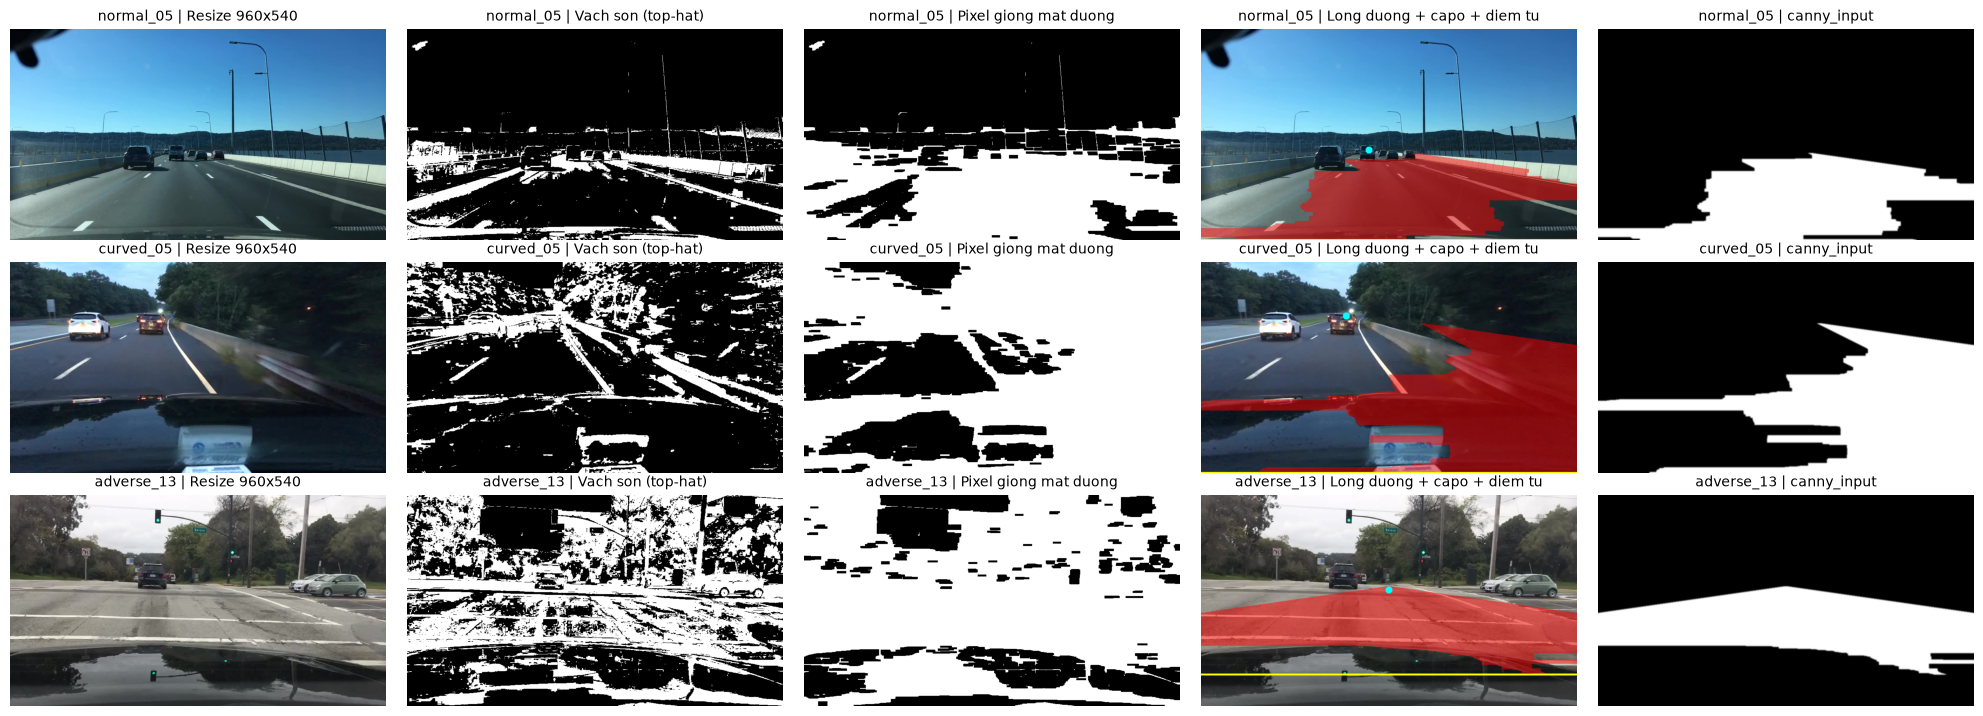

In [3]:
pre = {}
for path, key in zip(image_paths, NAMES):
    pre[key] = preprocess_rgb(read_rgb(path))
    rel = Path(*key).with_suffix('.png')
    for sub, arr in [('canny_input', pre[key].canny_input), ('resized', pre[key].resized_rgb),
                     ('road_mask', pre[key].road_mask)]:
        (OUT / sub / rel).parent.mkdir(parents=True, exist_ok=True)
        Image.fromarray(arr).save(OUT / sub / rel)

ratio = np.mean([np.mean(r.road_mask > 0) for r in pre.values()])
print(f'Da xu ly {len(pre)} anh. Mat na long duong chiem trung binh {ratio:.2%} dien tich anh')


def road_panel(r):
    # Mat na long duong tren anh: do = long duong, vach vang = mep capo, cham xanh = diem tu
    panel = r.resized_rgb.copy()
    panel[r.road_mask > 0] = (0.5 * panel[r.road_mask > 0] + [127, 0, 0]).astype(np.uint8)
    cv2.line(panel, (0, r.hood_y), (panel.shape[1] - 1, r.hood_y), (255, 255, 0), 3)
    cv2.circle(panel, (int(r.vp[0]), int(r.vp[1])), 9, (0, 255, 255), -1)
    return panel


show([(n, [pre[(g, n)].resized_rgb, pre[(g, n)].lane_mask, pre[(g, n)].road_like,
           road_panel(pre[(g, n)]), pre[(g, n)].canny_input])
      for g, n in SAMPLES],
     ['Resize 960x540', 'Vach son (top-hat)', 'Pixel giong mat duong', 'Long duong + capo + diem tu', 'canny_input'],
     figsize_per=(4, 2.4))


## Bước 2. Canny

Cài bằng NumPy theo 4 bước:

1. **Làm mờ Gaussian** 5×5, σ = 1,4, dùng tích chập tách được (lọc theo hàng rồi theo cột).
2. **Sobel**: tính độ lớn gradient (chuẩn L2) và hướng gradient.
3. **Non-maximum suppression**: hướng được làm tròn về 0°, 45°, 90°, 135°. Chỉ giữ pixel lớn hơn hai láng giềng dọc theo hướng gradient.
4. **Ngưỡng kép + hysteresis** `(50, 150)`: giữ cạnh mạnh, rồi lan dần sang các cạnh yếu nối liền với chúng.

Tham số `(50, 150, σ = 1,4)` là bộ tham số được chọn ở phần Canny của nhóm.

In [4]:
def gaussian_kernel(size, sigma):
    ax = np.arange(size) - size // 2
    g = np.exp(-(ax ** 2) / (2 * sigma ** 2))
    return g / g.sum()


def convolve_separable(img, k):
    r = len(k) // 2
    p = np.pad(img, r, mode='reflect')
    tmp = sum(k[i] * p[:, i:i + img.shape[1]] for i in range(len(k)))
    return sum(k[i] * tmp[i:i + img.shape[0], :] for i in range(len(k)))


def gaussian_smooth(img, size=5, sigma=1.4):
    return convolve_separable(img.astype(np.float64), gaussian_kernel(size, sigma))


def sobel_gradient(img, l2=True):
    p = np.pad(img, 1, mode='reflect')
    h, w = img.shape
    a = lambda dy, dx: p[1 + dy:1 + dy + h, 1 + dx:1 + dx + w]
    gx = (a(-1, 1) + 2 * a(0, 1) + a(1, 1)) - (a(-1, -1) + 2 * a(0, -1) + a(1, -1))
    gy = (a(1, -1) + 2 * a(1, 0) + a(1, 1)) - (a(-1, -1) + 2 * a(-1, 0) + a(-1, 1))
    mag = np.hypot(gx, gy) if l2 else np.abs(gx) + np.abs(gy)
    return mag, np.arctan2(gy, gx)


def non_max_suppression(mag, theta):
    h, w = mag.shape
    p = np.pad(mag, 1)
    a = lambda dy, dx: p[1 + dy:1 + dy + h, 1 + dx:1 + dx + w]
    ang = np.rad2deg(theta) % 180
    n1 = np.zeros_like(mag)
    n2 = np.zeros_like(mag)
    for lo, hi, dy, dx in [(0, 22.5, 0, 1), (22.5, 67.5, 1, 1), (67.5, 112.5, 1, 0), (112.5, 157.5, 1, -1), (157.5, 180.01, 0, 1)]:
        m = (ang >= lo) & (ang < hi)
        n1[m] = a(dy, dx)[m]
        n2[m] = a(-dy, -dx)[m]
    return np.where((mag > n1) & (mag >= n2), mag, 0)


def double_threshold_hysteresis(nms, low, high):
    strong = nms >= high
    weak = nms >= low
    edges = strong.copy()
    while True:
        p = np.pad(edges, 1)
        near = np.zeros_like(edges)
        for dy in (-1, 0, 1):
            for dx in (-1, 0, 1):
                near |= p[1 + dy:1 + dy + edges.shape[0], 1 + dx:1 + dx + edges.shape[1]]
        new = weak & near
        if (new == edges).all():
            return (edges * 255).astype(np.uint8)
        edges = new


def canny_edges(img, low, high, sigma, size=5, l2=True):
    smooth = gaussian_smooth(img, size, sigma)
    mag, theta = sobel_gradient(smooth, l2)
    return double_threshold_hysteresis(non_max_suppression(mag, theta), low, high)

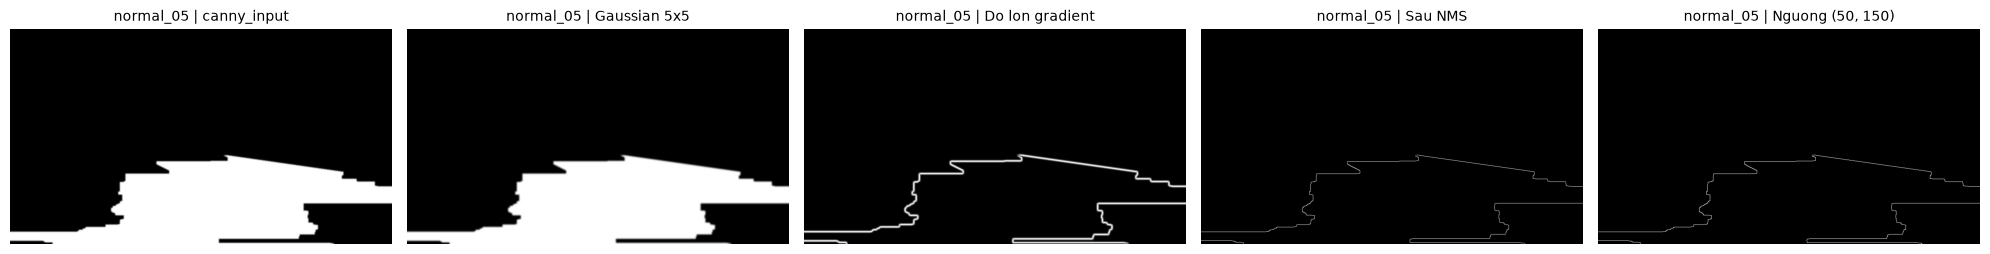

In [5]:
# Cac buoc trung gian cua Canny tren mot anh mau
img = pre[SAMPLES[0]].canny_input
smooth = gaussian_smooth(img, 5, 1.4)
mag, theta = sobel_gradient(smooth)
nms = non_max_suppression(mag, theta)
show([(SAMPLES[0][1], [img, smooth, mag, nms, double_threshold_hysteresis(nms, 50, 150)])],
     ['canny_input', 'Gaussian 5x5', 'Do lon gradient', 'Sau NMS', 'Nguong (50, 150)'], figsize_per=(4, 2.5))

Da chay Canny 50 anh trong 4.7 s. Mat do canh trung binh: 0.46%


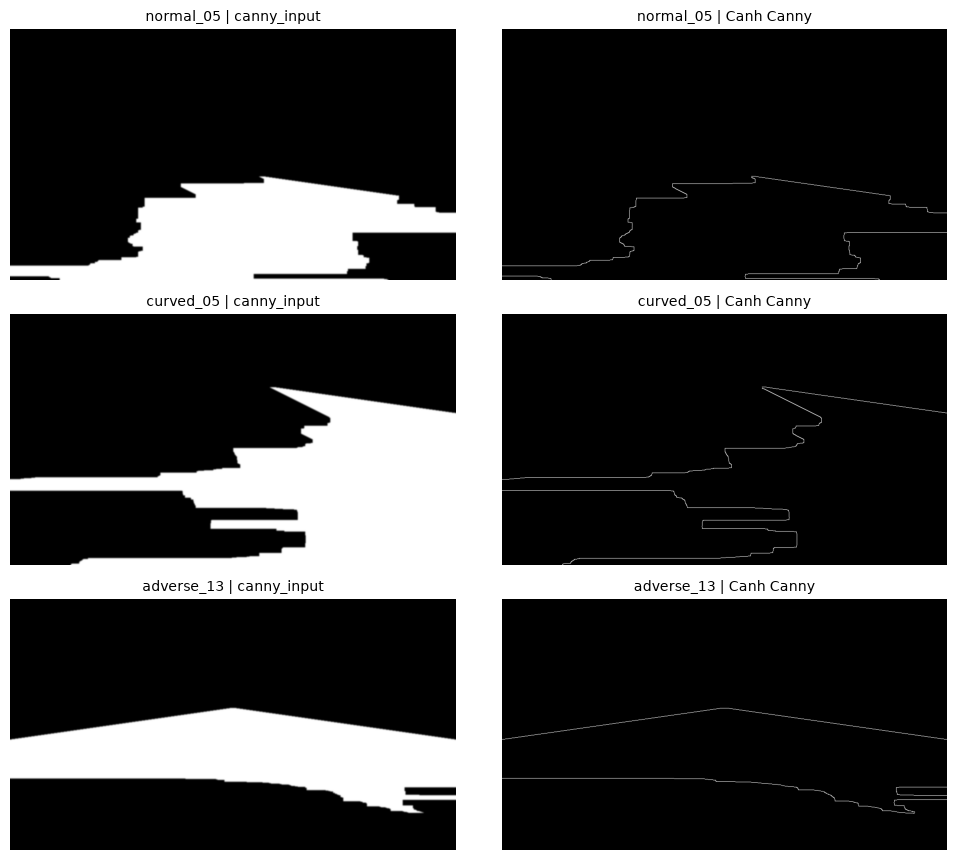

In [6]:
edges = {}
t0 = time.perf_counter()
for key in NAMES:
    edges[key] = canny_edges(pre[key].canny_input, 50, 150, 1.4)
    path = OUT / 'edges' / Path(*key).with_suffix('.png')
    path.parent.mkdir(parents=True, exist_ok=True)
    cv2.imwrite(str(path), edges[key])
print(f'Da chay Canny {len(edges)} anh trong {time.perf_counter() - t0:.1f} s. '
      f'Mat do canh trung binh: {np.mean([np.mean(e > 0) for e in edges.values()]):.2%}')

show([(n, [pre[(g, n)].canny_input, edges[(g, n)]]) for g, n in SAMPLES], ['canny_input', 'Canh Canny'])

## Bước 3. Biến đổi Hough và hậu xử lý

Canny giờ chạy trên mặt nạ lòng đường, nên mọi cạnh đều là ranh giới lòng đường. Hậu xử lý được sửa cho bài toán lòng đường:

1. **ROI thích nghi theo từng ảnh**: dải ngang từ y_v + 2% H (đường chân trời qua điểm tụ, kẹp trong 30–65% H) tới mép capo + 2% H, rộng hết W. Đường chân trời trong dataset dao động khoảng 35–55% H, mép capo khoảng 72–100% H, nên ROI cố định 48–98% H lúc thì cắt mất đường, lúc thì ăn vào capo. ROI không thu hẹp hai bên như hình thang cũ (đáy trên 35% W), vì biên lòng đường của đường rộng nằm ngoài hình thang đó.
2. **P-Hough** (`cv2.HoughLinesP`): ρ = 1 px, θ = 1°, ngưỡng 25 phiếu, đoạn dài tối thiểu 25 px, khoảng hở tối đa 25 px (giữ như cũ).
3. **Lọc độ dốc** `0,10 ≤ |m| ≤ 4` (cũ: 0,30). Trên đường rộng, biên lòng đường chỉ dốc khoảng 0,15–0,2, ngưỡng 0,30 sẽ loại mất. Đoạn có `m < 0` ở nửa trái là ứng viên biên trái, đoạn có `m > 0` ở nửa phải là ứng viên biên phải.
4. **Nhiều ứng viên mỗi bên**: tách lần lượt tối đa 4 cụm đồng thuận (mỗi cụm fit bằng WLS như bản cũ, rồi bỏ inlier của nó để tìm cụm kế tiếp), thêm ứng viên "không có biên". Ứng viên này nghĩa là biên nằm ngoài khung ảnh và đa giác chạy theo mép ảnh.
5. **Kiểm chứng bằng mặt nạ HSV** (đề xuất rồi kiểm chứng): với mỗi cặp (trái, phải), dựng đa giác lòng đường rồi chọn cặp có IoU lớn nhất với mặt nạ lòng đường HSV trong ROI. Hough cho biên thẳng và lấp lỗ trong mặt nạ; mặt nạ quyết định cặp nào đúng.
6. **Đa giác lòng đường**: vùng giữa hai biên trong ROI, cắt ở giao điểm hai biên. Biên nào ra khỏi khung thì đa giác đi tiếp dọc mép ảnh, thay vì bị cắt cụt ở hàng biên chạm mép như `create_road_polygon` cũ. Ở nhiều ảnh, ground truth phủ gần hết bề ngang ảnh ở các hàng 75–90% H, nên điều này quan trọng.


In [7]:
# Phan dau chep tu hough.py (detect_road_boundaries nhan them roi_vertices), dung cho ban goc o Buoc 5.
from typing import Literal


@dataclass(frozen=True)
class HoughConfig:
    """Cau hinh tham so cho ROI hinh thang va bien doi Hough."""

    # Tham so ROI hinh thang (ty le so voi W va H cua anh)
    roi_top_width_ratio: float = 0.35      # Be rong day tren ROI (~35% W)
    roi_bottom_width_ratio: float = 0.98   # Be rong day duoi ROI (~98% W)
    roi_top_y_ratio: float = 0.48          # Do cao canh tren ROI (~48% H, sat duong chan troi thuc te)
    roi_bottom_y_ratio: float = 0.98       # Do cao canh duoi ROI (~98% H)

    # Tham so HoughLinesP
    rho: float = 1.0                       # Do phan giai ban kinh (pixel)
    theta: float = np.pi / 180.0           # Do phan giai goc (rad, 1 do)
    threshold: int = 25                    # Nguong bo phieu tich luy toi thieu
    min_line_length: float = 25.0          # Chieu dai doan thang toi thieu (pixel)
    max_line_gap: float = 25.0             # Khoang cach toi da de noi cac doan dut quang (pixel)

    # Loc do doc m = dy / dx trong he toa do pixel (y huong xuong)
    # Bien trai: m < 0, bien phai: m > 0
    min_abs_slope: float = 0.30            # Loai bo cac duong qua nam ngang (~17 do)
    max_abs_slope: float = 4.00            # Loai bo cac duong gan nhu thang dung (~76 do)

    # Dung sai vuong goc khi chon cum dong thuan, ty le theo be rong anh.
    fit_distance_ratio: float = 0.02

    def __post_init__(self) -> None:
        values = np.array(list(self.__dict__.values()), dtype=float)
        if not np.all(np.isfinite(values)):
            raise ValueError("Tham so Hough phai huu han")
        if not (0.0 < self.roi_top_y_ratio < self.roi_bottom_y_ratio <= 1.0):
            raise ValueError("roi_top_y_ratio va roi_bottom_y_ratio khong hop le")
        if not (0.0 < self.roi_top_width_ratio <= self.roi_bottom_width_ratio <= 1.0):
            raise ValueError("Be rong ROI phai thoa 0 < top <= bottom <= 1")
        if not (0.0 < self.min_abs_slope < self.max_abs_slope):
            raise ValueError("Do doc phai thoa 0 < min < max")
        if self.rho <= 0 or not (0 < self.theta <= np.pi) or self.threshold <= 0:
            raise ValueError("rho, theta va threshold khong hop le")
        if self.min_line_length <= 0 or self.max_line_gap < 0:
            raise ValueError("Chieu dai phai duong, khoang dut doan khong am")
        if not (0 < self.fit_distance_ratio < 1):
            raise ValueError("fit_distance_ratio phai nam trong (0, 1)")


@dataclass(frozen=True)
class HoughResult:
    """Ket qua phat hien bien duong tu module Hough."""

    left_line: tuple[tuple[int, int], tuple[int, int]] | None    # ((x_bottom, y_bottom), (x_top, y_top))
    right_line: tuple[tuple[int, int], tuple[int, int]] | None   # ((x_bottom, y_bottom), (x_top, y_top))
    polygon: np.ndarray | None                                   # Toa do da giac (4, 2) mat duong giua 2 bien
    raw_lines: np.ndarray                                        # Mang tat ca doan thang HoughLinesP tim thay (N, 4)
    left_segments: np.ndarray                                    # Ung vien trai sau loc slope; fit chi dung inlier (K, 4)
    right_segments: np.ndarray                                   # Ung vien phai sau loc slope; fit chi dung inlier (M, 4)
    roi_mask: np.ndarray                                         # Mat na ROI da giac (H, W)


def get_trapezoid_vertices(height: int, width: int, config: HoughConfig) -> np.ndarray:
    """Tinh toa do 4 dinh cua ROI hinh thang can doi qua truc giua."""
    if height < 2 or width < 2:
        raise ValueError("Anh phai co it nhat 2 hang va 2 cot")
    center_x = width / 2.0
    top_y = min(height - 1, int(height * config.roi_top_y_ratio))
    bottom_y = min(height - 1, int(height * config.roi_bottom_y_ratio))

    half_top_w = (width * config.roi_top_width_ratio) / 2.0
    half_bottom_w = (width * config.roi_bottom_width_ratio) / 2.0

    top_left = (int(max(0, center_x - half_top_w)), top_y)
    top_right = (int(min(width - 1, center_x + half_top_w)), top_y)
    bottom_right = (int(min(width - 1, center_x + half_bottom_w)), bottom_y)
    bottom_left = (int(max(0, center_x - half_bottom_w)), bottom_y)

    return np.array([[bottom_left, top_left, top_right, bottom_right]], dtype=np.int32)


def apply_roi(edges: np.ndarray, vertices: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Ap dung mat na ROI hinh thang len anh canh Canny bang cv2.fillPoly.

    Tra ve: (roi_edges, roi_mask)
    """
    mask = np.zeros_like(edges, dtype=np.uint8)
    cv2.fillPoly(mask, vertices, 255)
    masked_edges = cv2.bitwise_and(edges, mask)
    return masked_edges, mask


def detect_hough_lines_p(roi_edges: np.ndarray, config: HoughConfig) -> np.ndarray:
    """Chay Probabilistic Hough Transform (cv2.HoughLinesP) tren vung ROI.

    Tra ve mang cac doan thang dang (N, 4) voi [x1, y1, x2, y2].
    Neu khong tim thay, tra ve mang rong kich thuoc (0, 4).
    """
    lines = cv2.HoughLinesP(
        roi_edges,
        rho=config.rho,
        theta=config.theta,
        threshold=config.threshold,
        minLineLength=config.min_line_length,
        maxLineGap=config.max_line_gap,
    )
    if lines is None:
        return np.empty((0, 4), dtype=np.int32)
    return lines.reshape(-1, 4).astype(np.int32)


def detect_hough_lines_standard(
    roi_edges: np.ndarray,
    config: HoughConfig,
) -> np.ndarray:
    """Chay Standard Hough Transform (cv2.HoughLines) phuc vu so sanh va nghien cuu.

    Tra ve mang cac duong thang dang (N, 2) voi [rho, theta].
    """
    lines = cv2.HoughLines(
        roi_edges,
        rho=config.rho,
        theta=config.theta,
        threshold=config.threshold,
    )
    if lines is None:
        return np.empty((0, 2), dtype=np.float32)
    return lines.reshape(-1, 2)


def split_left_right_segments(
    lines: np.ndarray,
    width: int,
    config: HoughConfig,
) -> tuple[np.ndarray, np.ndarray]:
    """Loc do doc va phan chia cac doan thang thanh 2 cum bien trai va bien phai.

    He toa do anh (goc (0,0) o goc tren-trai):
    - Bien trai huong ve vanishing point: dx > 0 khi dy < 0 => slope = dy / dx < 0.
    - Bien phai huong ve vanishing point: dx < 0 khi dy < 0 => slope = dy / dx > 0.
    - Cac doan thang nam ngang (|slope| < min_slope) hoac gan thang dung (|slope| > max_slope) bi loai.
    - Rang buoc khong gian: doan bien trai phai nam o phia ben trai (x_mid < 0.65 W),
      doan bien phai phai nam o phia ben phai (x_mid > 0.35 W).
    """
    if len(lines) == 0:
        return np.empty((0, 4), dtype=np.int32), np.empty((0, 4), dtype=np.int32)

    left_list: list[np.ndarray] = []
    right_list: list[np.ndarray] = []

    for seg in lines:
        x1, y1, x2, y2 = seg
        dx = x2 - x1
        dy = y2 - y1

        if dx == 0:
            # Duong thang dung hoan toan
            continue

        slope = dy / dx
        abs_slope = abs(slope)

        if not (config.min_abs_slope <= abs_slope <= config.max_abs_slope):
            continue

        x_mid = (x1 + x2) / 2.0

        if slope < 0 and x_mid < width * 0.65:
            left_list.append(seg)
        elif slope > 0 and x_mid > width * 0.35:
            right_list.append(seg)

    left_arr = np.array(left_list, dtype=np.int32) if left_list else np.empty((0, 4), dtype=np.int32)
    right_arr = np.array(right_list, dtype=np.int32) if right_list else np.empty((0, 4), dtype=np.int32)

    return left_arr, right_arr


def fit_boundary_line(
    segments: np.ndarray,
    y_bottom: int,
    y_top: int,
    *,
    side: Literal["left", "right"],
    width: int,
    config: HoughConfig,
) -> tuple[tuple[int, int], tuple[int, int]] | None:
    """Chon cum dong thuan tat dinh roi WLS x(y), khong tron moi doan cung dau.

    Moi doan de xuat mot mo hinh. Ca hai dau mut cua inlier phai cach mo
    hinh khong qua fit_distance_ratio * width pixel (khoang cach vuong goc).
    Chon tong chieu dai inlier lon nhat, hoa thi chon sai so nho nhat.
    """
    if side not in ("left", "right"):
        raise ValueError("side phai la left hoac right")
    if y_bottom <= y_top or width < 2:
        return None
    data = np.asarray(segments, dtype=np.float64).reshape(-1, 4)
    if len(data) == 0:
        return None
    dx = data[:, 2] - data[:, 0]
    dy = data[:, 3] - data[:, 1]
    slopes = np.divide(dy, dx, out=np.zeros_like(dy), where=dx != 0)
    valid = (
        np.all(np.isfinite(data), axis=1)
        & (dx != 0) & (dy != 0)
        & (np.abs(slopes) >= config.min_abs_slope)
        & (np.abs(slopes) <= config.max_abs_slope)
        & ((slopes < 0) if side == "left" else (slopes > 0))
    )
    data = data[valid]
    if len(data) == 0:
        return None
    lengths = np.hypot(data[:, 2] - data[:, 0], data[:, 3] - data[:, 1])
    # Sap xep de hoa diem khong phu thuoc thu tu cac doan Hough.
    order = np.lexsort(data.T[::-1])
    data, lengths = data[order], lengths[order]
    best_score = (-1.0, -np.inf)
    best_inliers = np.zeros(len(data), dtype=bool)
    for x1, y1, x2, y2 in data:
        k = (x2 - x1) / (y2 - y1)
        b = x1 - k * y1
        residuals = np.maximum(
            np.abs(data[:, 0] - k * data[:, 1] - b),
            np.abs(data[:, 2] - k * data[:, 3] - b),
        ) / np.hypot(1.0, k)
        inliers = residuals <= config.fit_distance_ratio * width
        support = float(lengths[inliers].sum())
        error = float(np.average(residuals[inliers], weights=lengths[inliers]))
        score = (support, -error)
        if score > best_score:
            best_score, best_inliers = score, inliers

    selected = data[best_inliers]
    weights = np.tile(lengths[best_inliers], 2)
    x_coords = np.concatenate((selected[:, 0], selected[:, 2]))
    y_coords = np.concatenate((selected[:, 1], selected[:, 3]))
    mean_y = np.average(y_coords, weights=weights)
    mean_x = np.average(x_coords, weights=weights)
    var_y = np.sum(weights * (y_coords - mean_y) ** 2)
    if var_y < 1e-5:
        return None
    k = np.sum(weights * (y_coords - mean_y) * (x_coords - mean_x)) / var_y
    if not np.isfinite(k) or k == 0:
        return None
    slope = 1.0 / k
    if not (config.min_abs_slope <= abs(slope) <= config.max_abs_slope):
        return None
    if (side == "left" and k >= 0) or (side == "right" and k <= 0):
        return None
    b = mean_x - k * mean_y
    return (
        (int(round(k * y_bottom + b)), y_bottom),
        (int(round(k * y_top + b)), y_top),
    )


def create_road_polygon(
    left_line: tuple[tuple[int, int], tuple[int, int]] | None,
    right_line: tuple[tuple[int, int], tuple[int, int]] | None,
) -> np.ndarray | None:
    """Tao vung chung hop le; chi giu phan nam duoi giao diem hai bien.

    Khong ngoai suy qua mien y cua mot trong hai bien. Hai bien dao thu tu
    tai day, khong co mien chung, hoac khong con dien tich thi tra ve None.
    """
    if left_line is None or right_line is None:
        return None
    if any(line[0][1] <= line[1][1] for line in (left_line, right_line)):
        return None

    def x_at(line, y):
        (xb, yb), (xt, yt) = line
        return xt + (xb - xt) * (y - yt) / (yb - yt)

    y_bottom = min(left_line[0][1], right_line[0][1])
    y_top = max(left_line[1][1], right_line[1][1])
    if y_top >= y_bottom:
        return None
    gap_bottom = x_at(right_line, y_bottom) - x_at(left_line, y_bottom)
    gap_top = x_at(right_line, y_top) - x_at(left_line, y_top)
    if gap_bottom < 1:
        return None
    if gap_top < 1:
        # Gap la ham bac nhat theo y. Giu it nhat 1 pixel o dinh.
        y_top += int(np.ceil((1 - gap_top) * (y_bottom - y_top) / (gap_bottom - gap_top)))
    if y_top >= y_bottom:
        return None
    polygon = np.array([
        [round(x_at(left_line, y_bottom)), y_bottom],
        [round(x_at(left_line, y_top)), y_top],
        [round(x_at(right_line, y_top)), y_top],
        [round(x_at(right_line, y_bottom)), y_bottom],
    ], dtype=np.int32)
    if polygon[0, 0] >= polygon[3, 0] or polygon[1, 0] >= polygon[2, 0]:
        return None
    return polygon


def detect_road_boundaries(
    edges: np.ndarray,
    config: HoughConfig | None = None,
    roi_vertices: np.ndarray | None = None,
) -> HoughResult:
    """Pipeline hoan chinh cua Phan 4: nhan anh canh Canny, tra ve 2 bien duong va da giac."""
    cfg = config or HoughConfig()
    if edges.ndim != 2 or edges.dtype != np.uint8:
        raise ValueError("Can anh canh uint8 mot kenh")
    height, width = edges.shape[:2]

    # 1. Tao va ap dung mat na ROI hinh thang (co dinh, hoac ROI thich nghi truyen tu ngoai)
    vertices = get_trapezoid_vertices(height, width, cfg) if roi_vertices is None else roi_vertices
    roi_edges, roi_mask = apply_roi(edges, vertices)

    # 2. P-Hough phat hien tap doan thang
    raw_lines = detect_hough_lines_p(roi_edges, cfg)

    # 3. Loc do doc va phan chia cum trai / phai
    left_segs, right_segs = split_left_right_segments(raw_lines, width, cfg)

    # 4. Hoi quy tuyen tinh co trong so de tim 2 duong bien
    y_bottom = int(vertices[0, 0, 1])
    y_top = int(vertices[0, 1, 1])

    left_line = fit_boundary_line(
        left_segs, y_bottom, y_top, side="left", width=width, config=cfg,
    )
    right_line = fit_boundary_line(
        right_segs, y_bottom, y_top, side="right", width=width, config=cfg,
    )

    def clip_line(line):
        if line is None:
            return None
        visible, bottom, top = cv2.clipLine((0, 0, width, height), *line)
        return (bottom, top) if visible and bottom[1] > top[1] else None

    left_line, right_line = clip_line(left_line), clip_line(right_line)

    # 5. Tao da giac vung duong giua 2 bien
    polygon = create_road_polygon(left_line, right_line)
    if polygon is not None:
        # Cung mien y, dung thu tu trai/phai, toa do trong khung anh.
        left_line = (tuple(map(int, polygon[0])), tuple(map(int, polygon[1])))
        right_line = (tuple(map(int, polygon[3])), tuple(map(int, polygon[2])))

    return HoughResult(
        left_line=left_line,
        right_line=right_line,
        polygon=polygon,
        raw_lines=raw_lines,
        left_segments=left_segs,
        right_segments=right_segs,
        roi_mask=roi_mask,
    )


def draw_hough_visualization(
    background_rgb: np.ndarray,
    result: HoughResult,
    draw_raw_lines: bool = False,
    draw_roi: bool = True,
) -> np.ndarray:
    """Ve cac ket qua phat hien len anh RGB goc de truc quan hoa va phan tich."""
    canvas = background_rgb.copy()

    # Ve da giac mat duong trong suot mau xanh la
    if result.polygon is not None:
        overlay = canvas.copy()
        cv2.fillPoly(overlay, [result.polygon], (0, 200, 0))
        cv2.addWeighted(overlay, 0.25, canvas, 0.75, 0, canvas)

    # Ve vien ROI hinh thang mau vang nhat
    if draw_roi:
        contours, _ = cv2.findContours(result.roi_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(canvas, contours, -1, (255, 255, 0), 1, lineType=cv2.LINE_AA)

    # Ve ung vien sau loc slope (RGB: trai do nhat, phai xanh lam nhat).
    if draw_raw_lines:
        for x1, y1, x2, y2 in result.left_segments:
            cv2.line(canvas, (x1, y1), (x2, y2), (255, 100, 100), 1, lineType=cv2.LINE_AA)
        for x1, y1, x2, y2 in result.right_segments:
            cv2.line(canvas, (x1, y1), (x2, y2), (100, 100, 255), 1, lineType=cv2.LINE_AA)

    # Ve hai bien duong chinh (bien trai do dam, bien phai xanh duong dam)
    if result.left_line is not None:
        pt1, pt2 = result.left_line
        cv2.line(canvas, pt1, pt2, (255, 0, 0), 3, lineType=cv2.LINE_AA)

    if result.right_line is not None:
        pt1, pt2 = result.right_line
        cv2.line(canvas, pt1, pt2, (0, 0, 255), 3, lineType=cv2.LINE_AA)

    return canvas


# ---------------------------------------------------------------------------
# Hau xu ly moi cho bai toan long duong (chi co trong notebook).
# Cac ham o tren (create_road_polygon, detect_road_boundaries) giu nguyen de tai tao ban goc o Buoc 5.
# ---------------------------------------------------------------------------

# Bien long duong thoai hon vach lan: tren duong rong |m| chi ~0,15-0,2, nen ha nguong doc xuong 0,10.
ROAD_HOUGH = HoughConfig(min_abs_slope=0.10)
TOP_K_CANDIDATES = 4


def boundary_candidates(segments, side, y_bottom, y_top, width, cfg, top_k=TOP_K_CANDIDATES):
    """Tach lan luot cac cum dong thuan: fit cum manh nhat, bo inlier cua no, fit tiep (toi da top_k)."""
    data = np.asarray(segments, dtype=np.float64).reshape(-1, 4)
    out = []
    while len(data) and len(out) < top_k:
        line = fit_boundary_line(data, y_bottom, y_top, side=side, width=width, config=cfg)
        if line is None:
            break
        out.append(line)
        (xb, yb), (xt, yt) = line
        k = (xb - xt) / (yb - yt)
        b = xt - k * yt
        residuals = np.maximum(np.abs(data[:, 0] - k * data[:, 1] - b),
                               np.abs(data[:, 2] - k * data[:, 3] - b)) / np.hypot(1.0, k)
        data = data[residuals > cfg.fit_distance_ratio * width]
    return out


def road_polygon_in_frame(left_line, right_line, y_top, y_bottom, width):
    """Vung giua hai bien trong [y_top, y_bottom], cat theo khung anh.

    Bien nao ra khoi anh thi da giac di tiep doc mep anh (khong bi cat cut nhu create_road_polygon).
    Bien None nghia la bien do nam ngoai khung, dung mep anh ben do. Bo phan phia tren giao diem hai bien.
    """
    def x_at(line, ys):
        (xb, yb), (xt, yt) = line
        return xt + (xb - xt) * (ys - yt) / (yb - yt)

    ys = np.arange(y_top, y_bottom + 1)
    xl = np.clip(x_at(left_line, ys), 0, width - 1) if left_line is not None else np.zeros(len(ys))
    xr = np.clip(x_at(right_line, ys), 0, width - 1) if right_line is not None else np.full(len(ys), width - 1.0)
    keep = xr - xl >= 1
    if keep.sum() < 2:
        return None
    keep[:np.argmax(keep)] = False
    ys, xl, xr = ys[keep], xl[keep], xr[keep]
    chain = np.concatenate([np.stack([xl, ys], 1), np.stack([xr, ys], 1)[::-1]]).astype(np.int32)
    polygon = cv2.approxPolyDP(chain.reshape(-1, 1, 2), 1.0, True).reshape(-1, 2)
    return polygon if len(polygon) >= 3 else None


def detect_road_region(edges, road_mask, roi_vertices, config=ROAD_HOUGH):
    """Hough de xuat, mat na long duong HSV kiem chung.

    Moi ben lay toi da TOP_K_CANDIDATES cum dong thuan lam ung vien, them ung vien None (mep anh).
    Chon cap (trai, phai) co da giac trung khop nhat (IoU) voi mat na long duong HSV trong ROI.
    """
    if edges.ndim != 2 or edges.dtype != np.uint8:
        raise ValueError('Can anh canh uint8 mot kenh')
    height, width = edges.shape
    roi_edges, roi_mask = apply_roi(edges, roi_vertices)
    raw_lines = detect_hough_lines_p(roi_edges, config)
    left_segs, right_segs = split_left_right_segments(raw_lines, width, config)
    y_bottom, y_top = int(roi_vertices[0, :, 1].max()), int(roi_vertices[0, :, 1].min())
    lefts = boundary_candidates(left_segs, 'left', y_bottom, y_top, width, config) + [None]
    rights = boundary_candidates(right_segs, 'right', y_bottom, y_top, width, config) + [None]
    target = (road_mask > 0) & (roi_mask > 0)
    best = (-1.0, None, None, None)
    for left in lefts:
        for right in rights:
            polygon = road_polygon_in_frame(left, right, y_top, y_bottom, width)
            if polygon is None:
                continue
            pred = np.zeros_like(road_mask)
            cv2.fillPoly(pred, [polygon], 255)
            pred = pred > 0
            score = np.count_nonzero(pred & target) / max(1, np.count_nonzero(pred | target))
            if score > best[0]:
                best = (score, left, right, polygon)
    _, left, right, polygon = best
    return HoughResult(left, right, polygon, raw_lines, left_segs, right_segs, roi_mask)


Day tren ROI (% H): min 30, max 65; day duoi: min 72, max 100


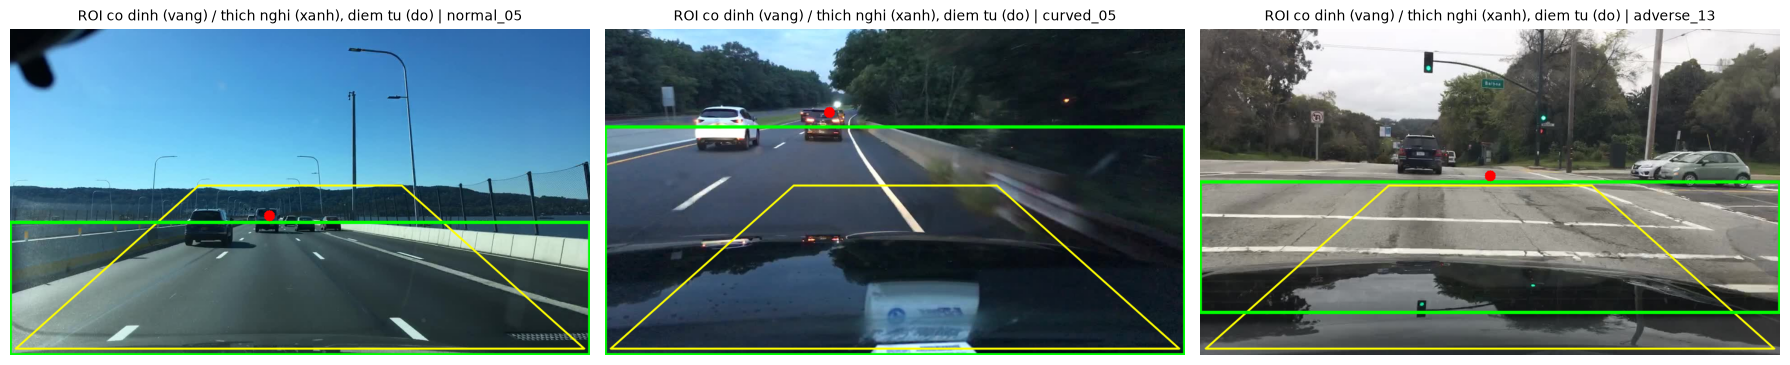

In [8]:
@dataclass(frozen=True)
class AdaptiveRoiConfig:
    top_offset_ratio: float = 0.02   # day tren nam duoi duong chan troi (qua diem tu) 2% H
    top_min_ratio: float = 0.30      # gioi han day tren trong [30%, 65%] H
    top_max_ratio: float = 0.65
    bottom_pad_ratio: float = 0.02   # day duoi = mep capo + 2% H


def adaptive_roi_vertices(pre, cfg=AdaptiveRoiConfig()):
    """ROI thich nghi: dai ngang tu ngay duoi duong chan troi toi mep nap capo, rong het W.

    Canh Canny gio chi den tu mat na long duong, nen ROI khong can thu hep hai ben; viec cua no la
    chan phan tren chan troi va nap capo. Thu tu dinh nhu get_trapezoid_vertices.
    """
    h, w = pre.road_mask.shape
    y_top = int(np.clip(pre.vp[1] + cfg.top_offset_ratio * h, cfg.top_min_ratio * h, cfg.top_max_ratio * h))
    y_bottom = max(min(h - 1, pre.hood_y + int(cfg.bottom_pad_ratio * h)), y_top + 40)
    return np.array([[[0, y_bottom], [0, y_top], [w - 1, y_top], [w - 1, y_bottom]]], dtype=np.int32)


def roi_panel(r, fixed, adaptive):
    # Vang = ROI co dinh cu, xanh la = ROI thich nghi, cham do = diem tu
    canvas = r.resized_rgb.copy()
    cv2.polylines(canvas, fixed, True, (255, 255, 0), 2, lineType=cv2.LINE_AA)
    cv2.polylines(canvas, adaptive, True, (0, 255, 0), 4, lineType=cv2.LINE_AA)
    cv2.circle(canvas, (int(r.vp[0]), int(r.vp[1])), 9, (255, 0, 0), -1)
    return canvas


rois = {key: adaptive_roi_vertices(pre[key]) for key in NAMES}
print('Day tren ROI (% H): min {:.0f}, max {:.0f}; day duoi: min {:.0f}, max {:.0f}'.format(
    *[f(v[0, i, 1] / 5.4 for v in rois.values()) for i, f in [(1, min), (1, max), (0, min), (0, max)]]))
fixed_roi = get_trapezoid_vertices(540, 960, HoughConfig())
show([('ROI co dinh (vang) / thich nghi (xanh), diem tu (do)',
       [roi_panel(pre[(g, n)], fixed_roi, rois[(g, n)]) for g, n in SAMPLES])],
     [n for _, n in SAMPLES], figsize_per=(6, 3.6))


Da chay Hough 50 anh, ket qua ve trong D:\PrjIP\canny-hough\outputs\pipeline_notebook\hough


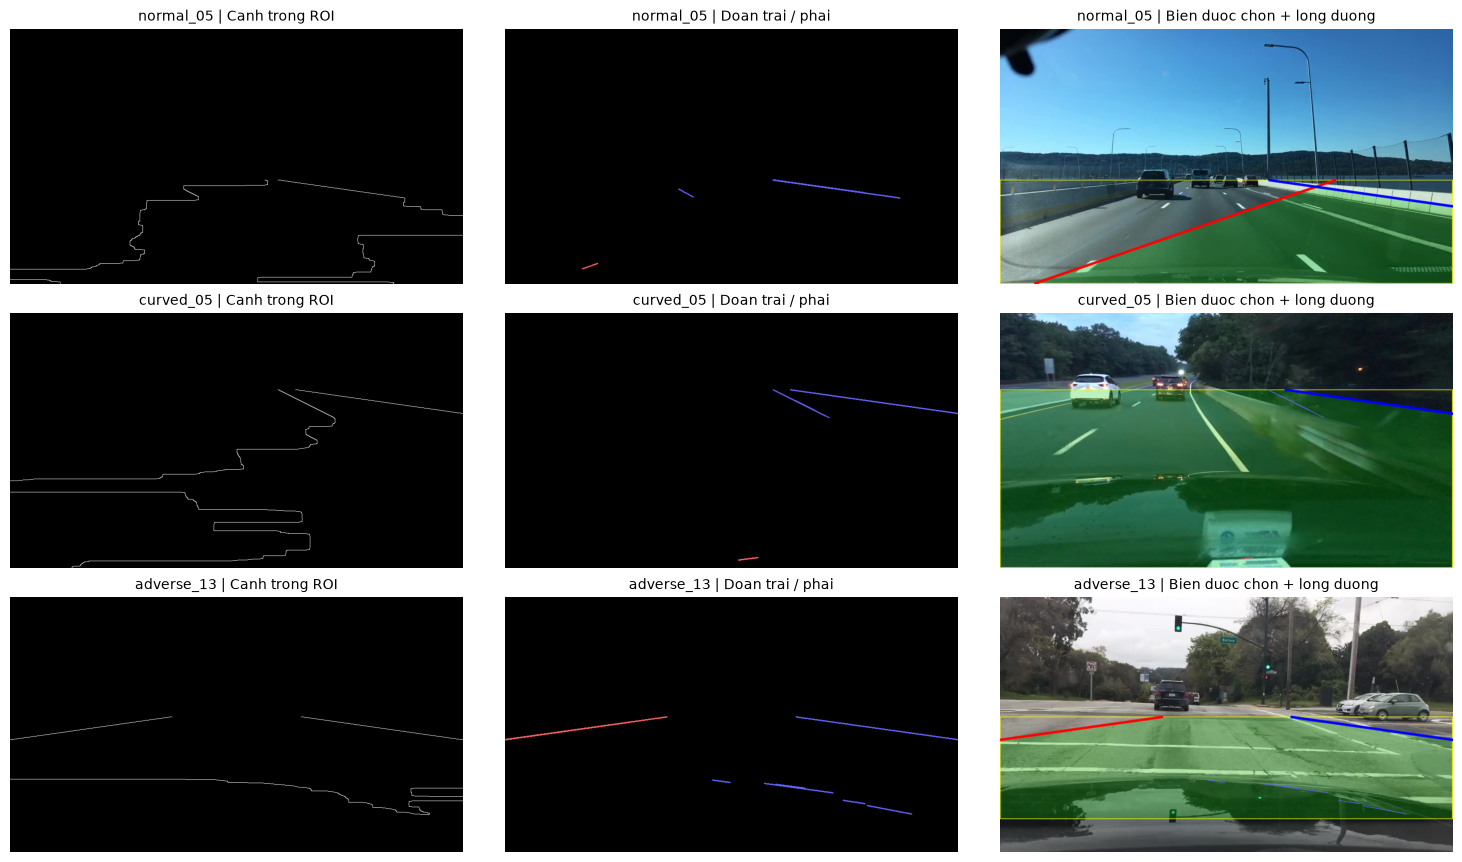

In [9]:
hough, runtime_ms = {}, {}
for key in NAMES:
    t0 = time.perf_counter()
    hough[key] = detect_road_region(edges[key], pre[key].road_mask, adaptive_roi_vertices(pre[key]))
    runtime_ms[key] = (time.perf_counter() - t0) * 1000
    vis = draw_hough_visualization(pre[key].resized_rgb, hough[key])
    path = OUT / 'hough' / Path(*key).with_suffix('.png')
    path.parent.mkdir(parents=True, exist_ok=True)
    cv2.imwrite(str(path), cv2.cvtColor(vis, cv2.COLOR_RGB2BGR))
print('Da chay Hough', len(hough), 'anh, ket qua ve trong', OUT / 'hough')


def segments_canvas(r, shape):
    # Cung mau voi duong bien o cot cuoi: doan trai do, doan phai xanh
    canvas = np.zeros((*shape, 3), dtype=np.uint8)
    for x1, y1, x2, y2 in r.left_segments:
        cv2.line(canvas, (x1, y1), (x2, y2), (255, 100, 100), 2)
    for x1, y1, x2, y2 in r.right_segments:
        cv2.line(canvas, (x1, y1), (x2, y2), (100, 100, 255), 2)
    return canvas


show([(n, [cv2.bitwise_and(edges[(g, n)], hough[(g, n)].roi_mask),
           segments_canvas(hough[(g, n)], edges[(g, n)].shape),
           draw_hough_visualization(pre[(g, n)].resized_rgb, hough[(g, n)], draw_raw_lines=True)])
      for g, n in SAMPLES],
     ['Canh trong ROI', 'Doan trai / phai', 'Bien duoc chon + long duong'])

## Bước 4. Đánh giá trên mặt nạ lòng đường

Ground truth là mặt nạ **vùng lòng đường**, resize về 960×540. Đánh giá được làm lại trên mặt nạ thay cho `evaluation.py`, vì đa giác lòng đường mới có thể có nhiều hơn 4 đỉnh (đi dọc mép ảnh):

- **IoU, precision, recall, F1** tính theo pixel trên toàn ảnh, lấy trung bình trên **tất cả** ảnh. Ảnh không có đa giác được tính là dự đoán rỗng (IoU = 0). Precision, recall, F1 là bộ chỉ số chuẩn của KITTI Road benchmark (Fritsch et al., 2013). Với đa giác 4 đỉnh, IoU ở đây trùng với IoU của `evaluation.py`, nên vẫn so sánh được với số liệu cũ.
- **MAE (px)**: tại 3 hàng `y = 60%, 75%, 90% H`, lấy trung bình khoảng cách giữa mép trái/phải của mặt nạ dự đoán và mép trái/phải của ground truth. Hàng mà ground truth rỗng (ví dụ nắp capo) được bỏ qua. Nếu ground truth có đường mà dự đoán rỗng ở hàng đó thì ảnh không đo được MAE; luôn báo kèm số ảnh đo được.
- **SR15**: số ảnh có MAE < 15 px chia cho **toàn bộ** số ảnh.


In [10]:
# Danh gia tren mat na long duong (thay cho evaluation.py, chi dung trong notebook)
SAMPLE_ROWS = (0.60, 0.75, 0.90)
SUCCESS_MAE_PX = 15.0


def polygon_mask(polygon, shape):
    mask = np.zeros(shape, np.uint8)
    if polygon is not None:
        cv2.fillPoly(mask, [np.asarray(polygon, np.int32)], 255)
    return mask


def evaluate_road_mask(pred, ground_truth):
    """IoU, precision, recall, F1 tren pixel; MAE theo mep trai/phai cua mat na tai 3 hang.

    MAE chi tinh khi tai moi hang mau co long duong trong GT thi mat na du doan cung co pixel
    (hang GT rong, vi du nap capo, duoc bo qua). SR15 = MAE < 15 px, mau so la toan bo anh.
    """
    if pred.shape != ground_truth.shape:
        raise ValueError('Du doan va ground truth phai cung kich thuoc H x W')
    p, g = pred > 0, ground_truth > 0
    tp, fp, fn = np.count_nonzero(p & g), np.count_nonzero(p & ~g), np.count_nonzero(~p & g)
    iou = tp / (tp + fp + fn) if tp + fp + fn else 0.0
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    height = g.shape[0]
    errors, missing = [], False
    for ratio in SAMPLE_ROWS:
        y = min(height - 1, int(height * ratio))
        gx = np.flatnonzero(g[y])
        if len(gx) == 0:
            continue
        px = np.flatnonzero(p[y])
        if len(px) == 0:
            missing = True
            break
        errors.append((abs(px[0] - gx[0]) + abs(px[-1] - gx[-1])) / 2)
    mae = float(np.mean(errors)) if errors and not missing else None
    return {'iou': iou, 'precision': precision, 'recall': recall, 'f1': f1, 'mae': mae,
            'mae_evaluable': int(mae is not None), 'success_mae15': int(mae is not None and mae < SUCCESS_MAE_PX)}


def summarize_records(records):
    rows = []
    for group in [*records['group'].drop_duplicates(), 'all']:
        sub = records if group == 'all' else records[records['group'] == group]
        valid = sub[sub['mae_evaluable'] == 1]
        rows.append({
            'group': group, 'count': len(sub),
            'left_line_pct': sub['left_line'].mean() * 100, 'right_line_pct': sub['right_line'].mean() * 100,
            'polygon_pct': sub['polygon_available'].mean() * 100,
            'mean_iou_all': sub['iou'].mean(), 'std_iou_all': sub['iou'].std(ddof=0),
            'precision': sub['precision'].mean(), 'recall': sub['recall'].mean(), 'f1': sub['f1'].mean(),
            'mae_evaluable_count': len(valid), 'mean_mae_evaluable': valid['mae'].mean(),
            'success_mae15_pct': sub['success_mae15'].mean() * 100,
            'mean_runtime_ms': sub['runtime_ms'].mean(),
        })
    return pd.DataFrame(rows)


W, H = 960, 540
records = []
for g, n in NAMES:
    gt_path = GT_DIR / g / f'{n}.png'
    if not gt_path.exists():  # anh tu chon ngoai dataset, khong co ground truth
        print('Bo qua danh gia (khong co ground truth):', g, n)
        continue
    gt = cv2.resize(cv2.imread(str(gt_path), cv2.IMREAD_GRAYSCALE), (W, H), interpolation=cv2.INTER_NEAREST)
    r = hough[(g, n)]
    records.append(dict(group=g, image=n, raw_lines=len(r.raw_lines), left_line=int(r.left_line is not None),
                        right_line=int(r.right_line is not None), polygon_available=int(r.polygon is not None),
                        runtime_ms=runtime_ms[(g, n)], **evaluate_road_mask(polygon_mask(r.polygon, gt.shape), gt)))

df = pd.DataFrame(records)
if df.empty:
    print('Khong co anh nao co ground truth, bo qua danh gia.')
else:
    df.to_csv(OUT / 'results.csv', index=False)
    summary = summarize_records(df)
    summary.to_csv(OUT / 'group_statistics.csv', index=False)
    print('Chi tiet tung anh:', OUT / 'results.csv', '| Tong hop theo nhom:', OUT / 'group_statistics.csv')
    display(summary.round(3))


Chi tiet tung anh: D:\PrjIP\canny-hough\outputs\pipeline_notebook\results.csv | Tong hop theo nhom: D:\PrjIP\canny-hough\outputs\pipeline_notebook\group_statistics.csv


,group,count,left_line_pct,right_line_pct,polygon_pct,mean_iou_all,std_iou_all,precision,recall,f1,mae_evaluable_count,mean_mae_evaluable,success_mae15_pct,mean_runtime_ms
0,adverse,20,60.000,70.000,100.0,0.553,0.143,0.620,0.868,0.701,15,168.844,0.0,7.651
1,curved,12,66.667,75.000,100.0,0.561,0.145,0.575,0.964,0.707,12,159.840,0.0,6.811
2,normal,18,77.778,83.333,100.0,0.565,0.127,0.632,0.884,0.713,16,113.057,0.0,10.293
3,all,50,68.000,76.000,100.0,0.559,0.138,0.614,0.897,0.707,43,145.574,0.0,8.401


## Bước 5. So sánh (ablation)

Tất cả cấu hình được đánh giá bằng cùng một hàm `evaluate_road_mask`:

- **0. Baseline tầm thường**: tô kín cả dải ngang từ chân trời tới mép capo (lấy từ ROI thích nghi), không dùng biên trái/phải. Dùng để thấy phần nào của IoU chỉ đến từ việc đặt đúng giới hạn trên/dưới.
- **1. Bản gốc**: ngưỡng HSV cố định + ROI cố định + Hough cũ, bắt vạch kẻ làn.
- **2. Bản trước**: vạch top-hat + ROI hình thang thích nghi + Hough cũ, vẫn bắt vạch kẻ làn.
- **3. Mặt nạ lòng đường HSV**, đầu ra của Bước 1, chưa qua Canny/Hough.
- **4. Bản mới**: lòng đường HSV → Canny → Hough kiểm chứng.


Chi tiet: D:\PrjIP\canny-hough\outputs\pipeline_notebook\ablation.csv | Tong hop: D:\PrjIP\canny-hough\outputs\pipeline_notebook\ablation_summary.csv


,mean_iou_all,precision,recall,f1,mae_evaluable_count,mean_mae_evaluable,success_mae15_pct,iou_adverse,iou_curved,iou_normal
variant,,,,,,,,,,
0. Dai chan troi -> capo (baseline tam thuong),0.552,0.570,0.961,0.700,44,153.604,4.0,0.563,0.521,0.561
1. Ban goc: vach HSV nguong co dinh + ROI co dinh,0.174,0.358,0.218,0.256,20,234.475,0.0,0.166,0.192,0.172
2. Ban truoc: vach top-hat + ROI thich nghi,0.308,0.643,0.365,0.445,31,213.425,0.0,0.217,0.405,0.344
3. Mat na long duong HSV (chua qua Hough),0.500,0.702,0.687,0.646,42,182.796,2.0,0.455,0.512,0.542
4. Ban moi: long duong HSV -> Canny -> Hough kiem chung,0.559,0.614,0.897,0.707,43,145.574,0.0,0.553,0.561,0.565


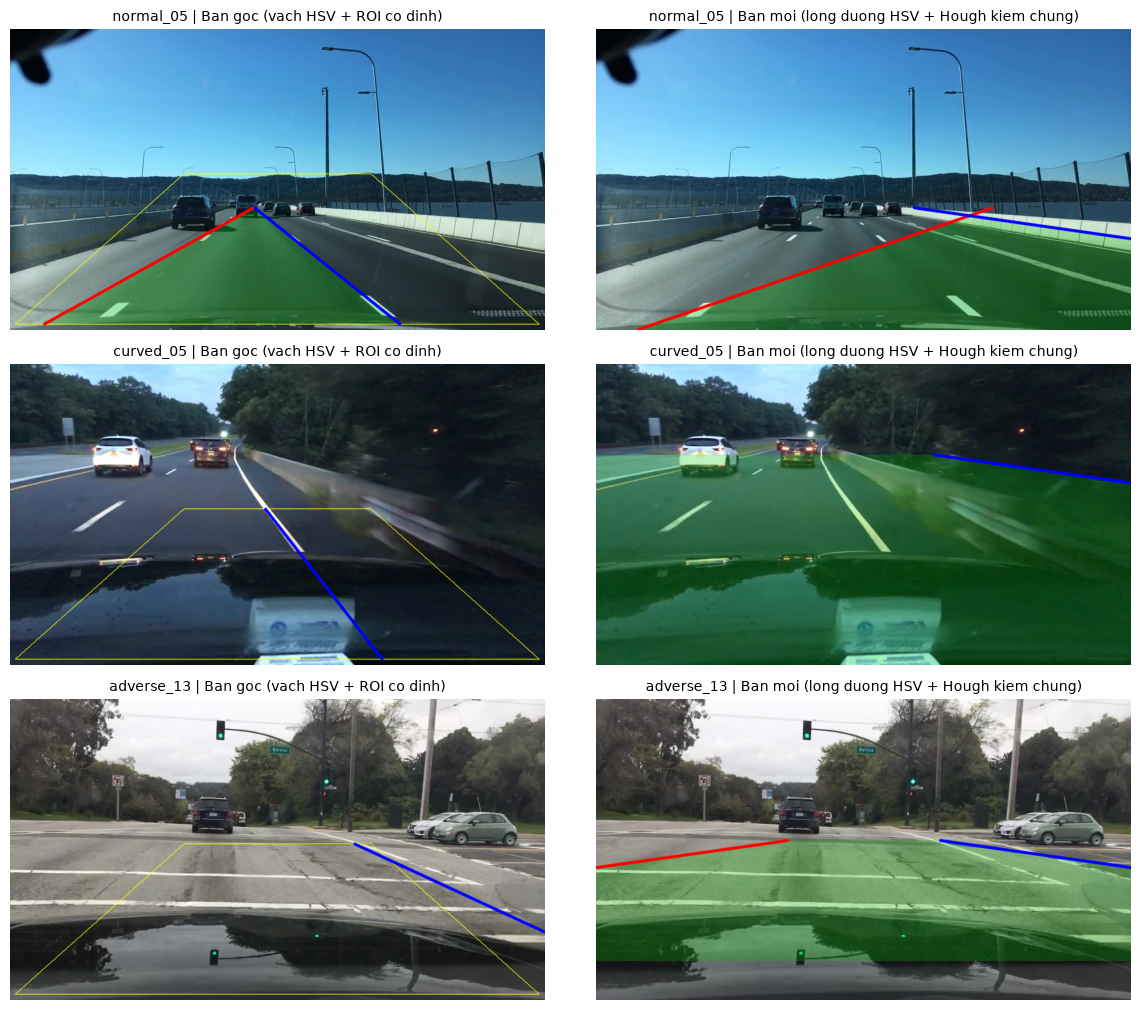

In [11]:
def lane_marking_mask_baseline(hsv):
    # Nguong co dinh cua preprocessing.py (ban goc)
    hue, saturation, value = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    white = (saturation <= 80) & (value >= 170)
    yellow = (hue >= 15) & (hue <= 40) & (saturation >= 70) & (value >= 90)
    return np.where(white | yellow, 255, 0).astype(np.uint8)


def lane_canny_input(rgb, mask):
    # Cach tao canny_input cu: giu pixel trong mat na vach, Gaussian (PIL, ban kinh 1,2), chuyen xam
    kept = Image.fromarray(np.where(mask[..., None] > 0, rgb, 0).astype(np.uint8))
    blurred = np.asarray(kept.filter(ImageFilter.GaussianBlur(radius=1.2))).astype(np.float32)
    gray = 0.299 * blurred[..., 0] + 0.587 * blurred[..., 1] + 0.114 * blurred[..., 2]
    return np.clip(np.rint(gray), 0, 255).astype(np.uint8)


def lane_roi_v2(p, h=540, w=960):
    # ROI thich nghi cua ban truoc: hinh thang, day tren rong 25% W dat tai diem tu
    y_top = int(np.clip(p.vp[1] + 0.02 * h, 0.30 * h, 0.65 * h))
    y_bottom = max(min(h - 1, p.hood_y + int(0.02 * h)), y_top + 40)
    half = 0.125 * w
    return np.array([[[0, y_bottom], [int(max(0, p.vp[0] - half)), y_top],
                      [int(min(w - 1, p.vp[0] + half)), y_top], [w - 1, y_bottom]]], dtype=np.int32)


VARIANTS = ['0. Dai chan troi -> capo (baseline tam thuong)', '1. Ban goc: vach HSV nguong co dinh + ROI co dinh',
            '2. Ban truoc: vach top-hat + ROI thich nghi', '3. Mat na long duong HSV (chua qua Hough)',
            '4. Ban moi: long duong HSV -> Canny -> Hough kiem chung']
rows, base_results = [], {}
for g, n in NAMES:
    gt_path = GT_DIR / g / f'{n}.png'
    if not gt_path.exists():
        continue
    gt = cv2.resize(cv2.imread(str(gt_path), cv2.IMREAD_GRAYSCALE), (W, H), interpolation=cv2.INTER_NEAREST)
    p, roi = pre[(g, n)], rois[(g, n)]
    band = np.zeros_like(gt)
    band[roi[0, :, 1].min():roi[0, :, 1].max() + 1] = 255
    r_base = detect_road_boundaries(canny_edges(lane_canny_input(p.resized_rgb, lane_marking_mask_baseline(p.hsv)), 50, 150, 1.4))
    r_v2 = detect_road_boundaries(canny_edges(lane_canny_input(p.resized_rgb, p.lane_mask), 50, 150, 1.4),
                                  roi_vertices=lane_roi_v2(p))
    base_results[(g, n)] = r_base
    preds = [band, polygon_mask(r_base.polygon, gt.shape), polygon_mask(r_v2.polygon, gt.shape),
             p.road_mask, polygon_mask(hough[(g, n)].polygon, gt.shape)]
    for name, pred in zip(VARIANTS, preds):
        rows.append(dict(variant=name, group=g, image=n, **evaluate_road_mask(pred, gt)))

abl = pd.DataFrame(rows)
if abl.empty:
    print('Khong co anh nao co ground truth, bo qua so sanh.')
else:
    abl.to_csv(OUT / 'ablation.csv', index=False)
    table = abl.groupby('variant').agg(
        mean_iou_all=('iou', 'mean'), precision=('precision', 'mean'), recall=('recall', 'mean'), f1=('f1', 'mean'),
        mae_evaluable_count=('mae_evaluable', 'sum'), mean_mae_evaluable=('mae', 'mean'),
        success_mae15_pct=('success_mae15', lambda s: s.mean() * 100))
    table = table.join(abl.pivot_table(index='variant', columns='group', values='iou', aggfunc='mean').add_prefix('iou_'))
    table.to_csv(OUT / 'ablation_summary.csv')
    print('Chi tiet:', OUT / 'ablation.csv', '| Tong hop:', OUT / 'ablation_summary.csv')
    display(table.round(3))
    keys = [k for k in SAMPLES if k in base_results]
    show([(n, [draw_hough_visualization(pre[(g, n)].resized_rgb, base_results[(g, n)]),
               draw_hough_visualization(pre[(g, n)].resized_rgb, hough[(g, n)], draw_roi=False)]) for g, n in keys],
         ['Ban goc (vach HSV + ROI co dinh)', 'Ban moi (long duong HSV + Hough kiem chung)'], figsize_per=(6, 3.4))


## Nhận xét kết quả

Số liệu lấy từ bảng ở Bước 5 (50 ảnh, mẫu số là toàn bộ ảnh, đánh giá trên mặt nạ).

| Cấu hình | IoU | Precision | Recall | F1 | MAE (số ảnh đo được) | IoU normal / curved / adverse |
|---|---|---|---|---|---|---|
| 0. Dải chân trời → capo (tầm thường) | 0,552 | 0,570 | 0,961 | 0,700 | 153,6 px (44) | 0,561 / 0,521 / 0,563 |
| 1. Bản gốc (vạch, ngưỡng cố định, ROI cố định) | 0,174 | 0,358 | 0,218 | 0,256 | 234,5 px (20) | 0,172 / 0,192 / 0,166 |
| 2. Bản trước (vạch top-hat, ROI thích nghi) | 0,308 | 0,643 | 0,365 | 0,445 | 213,4 px (31) | 0,344 / 0,405 / 0,217 |
| 3. Mặt nạ lòng đường HSV | 0,500 | **0,702** | 0,687 | 0,646 | 182,8 px (42) | 0,542 / 0,512 / 0,455 |
| **4. Bản mới (lòng đường HSV → Canny → Hough kiểm chứng)** | **0,559** | 0,614 | 0,897 | **0,707** | **145,6 px (43)** | 0,565 / 0,561 / 0,553 |

Ghi chú: cấu hình 2 đạt 0,308 thay vì 0,278 như lần trước, vì mép capo của ROI giờ lấy từ phép quét hàng mới. Thuật toán bắt vạch thì không đổi.

**Điểm tốt lên**

- Đổi mục tiêu từ vạch kẻ làn sang lòng đường làm IoU tăng từ 0,174 lên 0,559 và F1 từ 0,256 lên 0,707. Cả 50/50 ảnh đều có IoU cao hơn bản gốc. Recall tăng từ 0,22 lên 0,90: bản gốc chỉ phủ làn xe đang đi, bản mới phủ cả lòng đường.
- Đưa Hough vào sau mặt nạ HSV có ích: IoU tăng từ 0,500 lên 0,559, MAE giảm từ 182,8 xuống 145,6 px. Hough làm thẳng mép và lấp các lỗ của mặt nạ; mặt nạ chọn ra cặp biên đúng.
- Kết quả đều giữa ba nhóm (0,553–0,565). Nhóm adverse không còn tụt lại như bản lần trước (0,174).

**Điểm cần nói rõ khi viết báo cáo**

- **Baseline tầm thường đã đạt IoU 0,552.** Chỉ cần tô kín dải ngang từ đường chân trời (điểm tụ) tới mép capo là đã được 0,552, vì ground truth phủ phần lớn bề ngang ảnh. Bản mới (0,559) chỉ hơn baseline này rất ít: tốt hơn ở 29 ảnh, kém hơn ở 10 ảnh, ngang nhau ở 11 ảnh. Nghĩa là phần lớn IoU đến từ việc đặt đúng **giới hạn trên/dưới** (ROI thích nghi). Việc tách **biên trái/phải** mới tăng precision từ 0,570 lên 0,614. Bản gốc (0,174) thấp hơn baseline tầm thường rất xa, chủ yếu vì nó chỉ khoanh vùng làn xe.
- **Giới hạn của màu HSV:** vỉa hè xám, tường chắn bê tông và nắp capo phản chiếu có S, V gần giống nhựa đường. Ví dụ ở curved_05, mặt nạ tràn sang tường và ăn cả capo. Ngược lại, ở mặt đường có hai tông sáng khác nhau (normal_05, normal_01), mặt nạ bị hụt một nửa. Đây là các ảnh kém hơn baseline nhiều nhất (adverse_05 −0,29, normal_05 −0,22, normal_01 −0,22).
- **MAE và SR15 vẫn cao/thấp** (145,6 px; SR15 = 0%). MAE đo ở mép ngoài cùng của vùng, nên chỉ cần lệch một vệt nhỏ (xe đỗ, lề) là sai số đã lớn.
- Tham số được chọn trên chính 50 ảnh, chưa có tập kiểm tra riêng. Khi quét thử, IoU dao động trong khoảng 0,55–0,57, nên chênh lệch khoảng ±0,01 là nhiễu.

**Hướng tiếp theo**

1. Thêm **rào chắn cạnh** khi quét hàng: dừng tại cạnh Canny mạnh trên kênh S/H (mép vỉa hè, cỏ, tường). Kênh S/H ít bị bóng đổ và vạch trắng ảnh hưởng hơn kênh V. Việc này nhắm vào lỗi tràn ở curved_05.
2. **Mô hình màu cập nhật theo hàng** (cập nhật trung vị S, V của đoạn đường đã nhận khi quét lên), để không hụt vùng khi mặt đường đổi tông sáng như normal_05.
3. Trong báo cáo, luôn đặt kết quả cạnh baseline tầm thường để người đọc thấy rõ phần đóng góp của bước tách biên.

**Tài liệu tham khảo**

- Zuiderveld, K. (1994). Contrast Limited Adaptive Histogram Equalization. *Graphics Gems IV*, 474–485.
- Sotelo, M. A. et al. (2004). A color vision-based lane tracking system for autonomous driving on unmarked roads. *Autonomous Robots*, 16(1), 95–116.
- Alvarez, J. M., & López, A. M. (2011). Road detection based on illuminant invariance. *IEEE Trans. Intelligent Transportation Systems*, 12(1), 184–193.
- Cucchiara, R. et al. (2003). Detecting moving objects, ghosts, and shadows in video streams. *IEEE Trans. PAMI*, 25(10), 1337–1342.
- Veit, T. et al. (2008). Evaluation of road marking feature extraction. *IEEE ITSC 2008*, 174–181.
- Barnard, S. T. (1983). Interpreting perspective images. *Artificial Intelligence*, 21(4), 435–462.
- Kong, H., Audibert, J.-Y., & Ponce, J. (2009). Vanishing point detection for road detection. *CVPR 2009*, 96–103.
- Fritsch, J., Kühnl, T., & Geiger, A. (2013). A new performance measure and evaluation benchmark for road detection algorithms. *IEEE ITSC 2013*, 1693–1700.
